# ML Capstone Review 2 — Clustering (Easy Student Version)
**Project:** Healthcare Cost Prediction and Patient Risk Intelligence Platform  
**Dataset:** `medical_insurance.csv`  
**Algorithms:** 1. K-Means, 2. Agglomerative Hierarchical, 3. Divisive Hierarchical (Bisecting K-Means).  

**Important:** The first **two** methods are compulsory in the faculty rubric. **Divisive** is added for extra comparison. Every algorithm is fitted on the **same 1,200 sampled patient records** and gets metrics, PCA scatter plot, and a bar chart of cluster sizes. Training **does not use class labels**.

**How to present:** Run all cells from top to bottom. After each result, explain how the model forms clusters, how many patients are in each cluster, and what the metrics mean. The observations must be written by your team.

**Dashboard note:** Run the script `scripts/save_cluster_model.py` once to produce the K-Means model for the interactive GUI, or use the included ready-to-run saved model.

## Step 1 — Import the libraries
We use Pandas to read data, scikit-learn to run algorithms, and Matplotlib/Seaborn to draw graphs.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, BisectingKMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import linkage, dendrogram

np.random.seed(42)
sns.set_theme(style="whitegrid")
print("Libraries imported successfully")

Libraries imported successfully


## Step 2 — Read and check the dataset
The notebook works when Jupyter starts in either the project root or `notebooks/`. We check missing values, duplicate rows and the first few records.

In [2]:
file_path = "data/medical_insurance.csv"
results_folder = "results"

if not os.path.exists(file_path):
    file_path = "../data/medical_insurance.csv"
    results_folder = "../results"

os.makedirs(results_folder, exist_ok=True)

df = pd.read_csv(file_path)
print("Dataset size:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Missing values in each column:")
print(df.isnull().sum()[df.isnull().sum() > 0])
display(df.head())

Dataset size: (100000, 54)
Total missing values: 30083
Duplicate rows: 0
Missing values in each column:
alcohol_freq    30083
dtype: int64


,person_id,age,sex,region,urban_rural,income,education,marital_status,employment_status,household_size,dependents,bmi,smoker,alcohol_freq,visits_last_year,hospitalizations_last_3yrs,days_hospitalized_last_3yrs,medication_count,systolic_bp,diastolic_bp,ldl,hba1c,plan_type,network_tier,deductible,copay,policy_term_years,policy_changes_last_2yrs,provider_quality,risk_score,annual_medical_cost,annual_premium,monthly_premium,claims_count,avg_claim_amount,total_claims_paid,chronic_count,hypertension,diabetes,asthma,copd,cardiovascular_disease,cancer_history,kidney_disease,liver_disease,arthritis,mental_health,proc_imaging_count,proc_surgery_count,proc_physio_count,proc_consult_count,proc_lab_count,is_high_risk,had_major_procedure
0,75722,52,Female,North,Suburban,22700.0,Doctorate,Married,Retired,3,1,27.4,Never,NaN,2,0,0,4,121.0,76.0,123.8,5.28,PPO,Bronze,1000,20,4,0,3.73,0.5714,6938.06,876.05,73.00,1,4672.59,4672.59,1,0,0,0,0,0,0,0,0,1,0,1,0,2,0,1,0,0
1,80185,79,Female,North,Urban,12800.0,No HS,Married,Employed,3,1,26.6,Never,Weekly,2,0,0,3,131.0,79.0,97.3,4.82,POS,Gold,1000,10,1,0,3.10,1.0000,1632.61,445.10,37.09,4,297.27,1189.08,2,0,0,0,0,0,0,0,0,1,1,0,0,1,0,1,1,0
2,19865,68,Male,North,Rural,40700.0,HS,Married,Retired,5,3,31.5,Never,NaN,1,0,0,4,160.0,84.0,129.5,5.51,HMO,Platinum,500,20,10,0,3.90,1.0000,7661.01,1538.02,128.17,0,0.00,0.00,3,1,0,0,0,0,1,0,0,0,1,1,0,2,1,0,1,0
3,76700,15,Male,North,Suburban,15600.0,Some College,Married,Self-employed,5,3,31.6,Never,NaN,0,0,0,1,104.0,68.0,160.3,8.50,HMO,Silver,500,20,5,0,3.89,0.2857,5130.27,820.63,68.39,0,0.00,0.00,1,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0
4,92992,53,Male,Central,Suburban,89600.0,Doctorate,Married,Self-employed,2,0,30.5,Never,Daily,3,0,0,2,136.0,83.0,171.0,5.20,POS,Platinum,500,10,7,0,3.90,0.8681,1700.73,500.93,41.74,1,1002.24,1002.24,2,1,0,0,0,0,0,0,0,1,0,2,0,1,1,0,1,0


## Step 3 — Basic EDA visualisations
These plots show the distributions of important numerical features. Write one original observation from the actual outputs for your presentation.

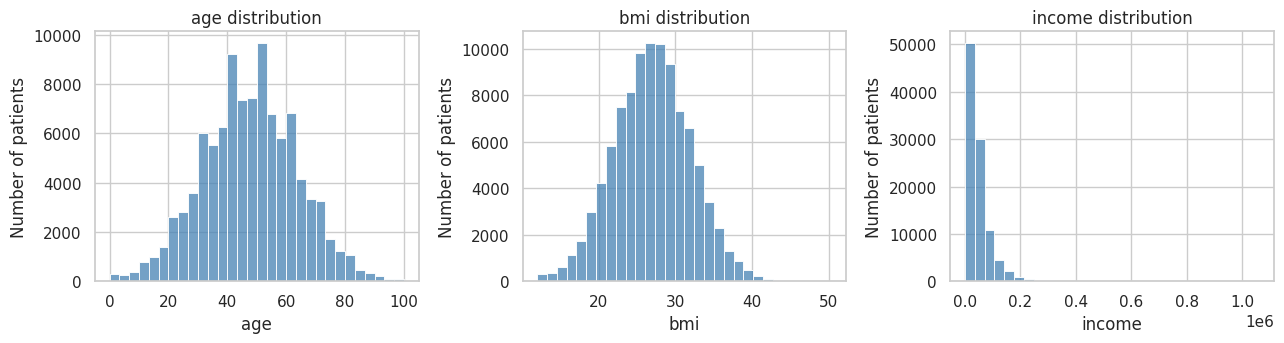

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for i, column in enumerate(["age", "bmi", "income"]):
    sns.histplot(df[column], bins=30, ax=axes[i], color="steelblue")
    axes[i].set_title(column + " distribution")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Number of patients")
plt.tight_layout()
plt.show()

## Step 4 — Seven easy feature-engineering columns
These are the same seven engineered features from our team's earlier classification work. They turn existing inputs into useful features for grouping patients. No outcome label is used in these formulas.

In [4]:
data = df.drop_duplicates().copy()

# 1. BMI groups
data["BMI_Category"] = pd.cut(
    data["bmi"], bins=[-np.inf, 18.5, 25, 30, np.inf],
    labels=["Underweight", "Normal", "Overweight", "Obese"], right=False
).astype(str)

# 2. Age groups
data["Age_Group"] = pd.cut(
    data["age"], bins=[-np.inf, 30, 56, np.inf],
    labels=["Youth", "Middle-aged", "Senior"], right=False
).astype(str)

# 3. Lifestyle risk indicator (defined by our team)
data["Lifestyle_Risk_Score"] = (
    np.where(data["smoker"] == "Current", 3,
             np.where(data["smoker"] == "Former", 1, 0))
    + (data["bmi"] >= 30).astype(int)
    + data["mental_health"].fillna(0) * 0.5
)

# 4. Visits and procedures summary
data["Hospital_Utilization_Score"] = (
    data["visits_last_year"]
    + 3 * data["hospitalizations_last_3yrs"]
    + 0.5 * data["days_hospitalized_last_3yrs"]
    + 2 * data["proc_surgery_count"]
    + data["proc_imaging_count"]
)

# 5. Premium and deductible ratio
data["Insurance_Coverage_Ratio"] = (
    data["annual_premium"] /
    (data["deductible"] + data["annual_premium"] + 0.00001)
)

# 6. Total number of listed chronic conditions
chronic = ["hypertension", "diabetes", "asthma", "copd",
           "cardiovascular_disease", "cancer_history", "kidney_disease",
           "liver_disease", "arthritis"]
data["Total_Chronic_Diseases"] = data[chronic].sum(axis=1)

# 7. Simple clinical and utilization index
data["Claim_Severity_Index"] = (
    0.05 * data["age"]
    + 0.1 * data["bmi"]
    + 1.5 * data["Total_Chronic_Diseases"]
    + 0.5 * data["Hospital_Utilization_Score"]
    + 1.5 * data["had_major_procedure"]
)

print("Feature engineering complete")
display(data[["BMI_Category", "Age_Group", "Lifestyle_Risk_Score",
              "Hospital_Utilization_Score", "Insurance_Coverage_Ratio",
              "Total_Chronic_Diseases", "Claim_Severity_Index"]].head())

Feature engineering complete


,BMI_Category,Age_Group,Lifestyle_Risk_Score,Hospital_Utilization_Score,Insurance_Coverage_Ratio,Total_Chronic_Diseases,Claim_Severity_Index
0,Overweight,Middle-aged,0.0,3.0,0.466965,1,8.34
1,Overweight,Senior,0.5,2.0,0.308006,1,9.11
2,Obese,Senior,1.5,2.0,0.754664,2,10.55
3,Obese,Youth,1.0,1.0,0.621393,1,5.91
4,Obese,Middle-aged,1.0,5.0,0.500465,2,11.20


## Step 5 — Remove outcomes, sample data, and scale it
Clustering is **unsupervised**. We exclude `is_high_risk`, `annual_medical_cost`, and derived outcome fields. We choose 1,200 records because agglomerative clustering is expensive on 100,000 patients. Every algorithm below uses exactly the same rows and transformed inputs.

`SimpleImputer` fills missing values, `OneHotEncoder` handles text categories, and `StandardScaler` puts numeric columns on comparable scales. There is **no test label** or prediction target in clustering. Scaling is fitted on the unsupervised clustering sample, not on a held-out test set.

In [5]:
# Do NOT use outcomes or identification columns for clustering
remove_columns = ["person_id", "annual_medical_cost", "is_high_risk",
                  "risk_score", "total_claims_paid", "avg_claim_amount"]

X = data.drop(columns=remove_columns)
X = X.sample(n=min(1200, len(X)), random_state=42)

# Categorical columns contain words; numerical columns contain numbers
categorical = X.select_dtypes(include=["object", "category"]).columns.tolist()
numerical = X.select_dtypes(include="number").columns.tolist()

preprocess = ColumnTransformer([
    ("numbers", Pipeline([
        ("fill", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), numerical),
    ("categories", Pipeline([
        ("fill", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), categorical)
])

X_scaled = preprocess.fit_transform(X)
print("Sample shape before preprocessing:", X.shape)
print("Sample shape after preprocessing:", X_scaled.shape)
print("Outcome columns excluded:", remove_columns)
assert np.isfinite(X_scaled).all()

Sample shape before preprocessing: (1200, 55)
Sample shape after preprocessing: (1200, 89)
Outcome columns excluded: ['person_id', 'annual_medical_cost', 'is_high_risk', 'risk_score', 'total_claims_paid', 'avg_claim_amount']


## Step 6 — Elbow curve and silhouette curve to choose K
**Elbow:** Inertia decreases as more groups are added; look for where the decrease starts slowing. **Silhouette:** Higher means better separation and cohesion. Both help discuss the choice of `k`. Here we use the highest sampled silhouette among 2–8 as a reproducible starting point, and your team should inspect the elbow before concluding.

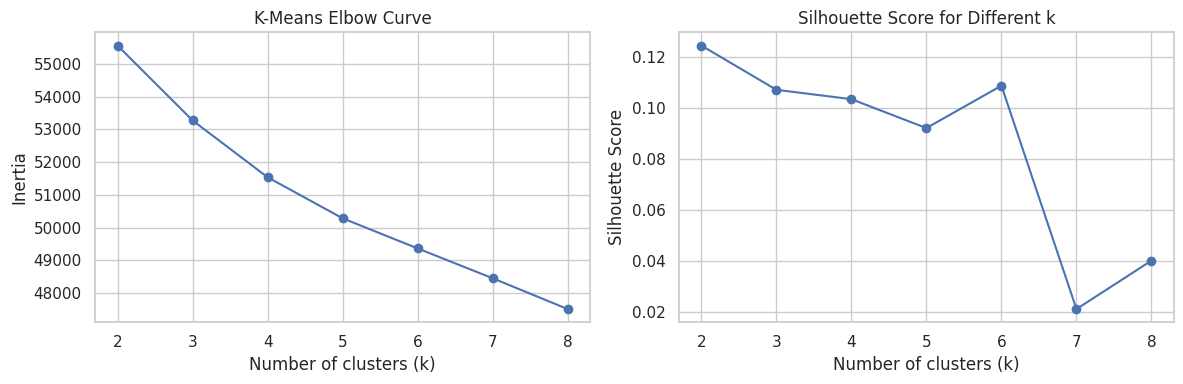

Chosen k: 2
Student explanation: Discuss whether the elbow also supports this value.


In [6]:
k_values = list(range(2, 9))
inertia_values = []
silhouette_values = []

for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(X_scaled)
    inertia_values.append(model.inertia_)
    silhouette_values.append(silhouette_score(
        X_scaled, labels, sample_size=600, random_state=42
    ))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_values, inertia_values, marker="o")
axes[0].set_title("K-Means Elbow Curve")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[1].plot(k_values, silhouette_values, marker="o")
axes[1].set_title("Silhouette Score for Different k")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette Score")
plt.tight_layout()
plt.show()

best_k = k_values[np.argmax(silhouette_values)]
print("Chosen k:", best_k)
print("Student explanation: Discuss whether the elbow also supports this value.")

## Step 7 — PCA visualisation used for every algorithm
PCA reduces many input columns to **two axes for plotting**. All three algorithms are still trained on the original scaled columns, **not** on this PCA view.

In [7]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print("PCA explained variance (two axes):", round(pca.explained_variance_ratio_.sum(), 3))

PCA explained variance (two axes): 0.176


## Step 8 — Required algorithm 1: K-Means
**Training:** `fit_predict()` learns centroids and assigns patient labels. **Testing/measurement:** Unsupervised clustering has no ground-truth target to predict against; we assess the fitted labels with Silhouette, Davies–Bouldin, and Calinski–Harabasz scores. The scatter plot colors patients by their cluster label.

K-Means results
Silhouette Score: 0.125 (higher is better)
Davies-Bouldin: 3.281 (lower is better)
Calinski-Harabasz: 104.35 (higher is better)
Number of patients per cluster:
0    444
1    756


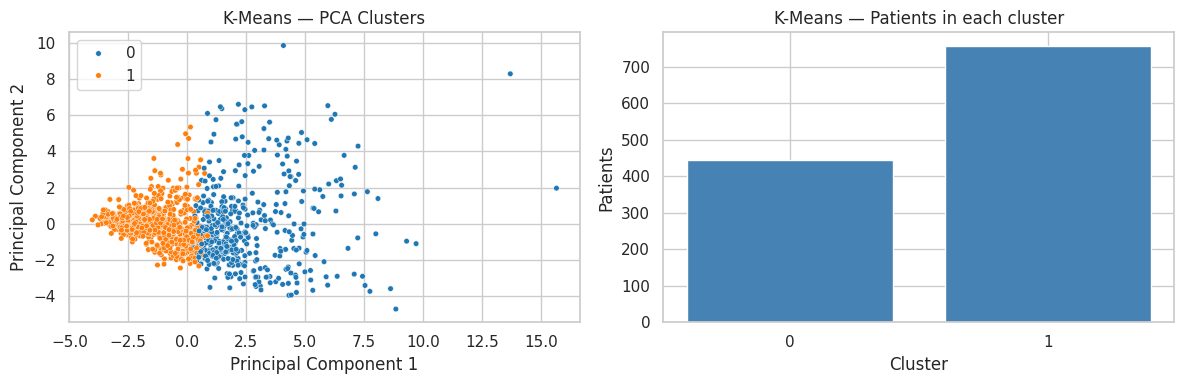

In [8]:
kmeans = KMeans(n_clusters=best_k, n_init=15, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

km_sil = silhouette_score(X_scaled, kmeans_labels, sample_size=600, random_state=42)
km_db = davies_bouldin_score(X_scaled, kmeans_labels)
km_ch = calinski_harabasz_score(X_scaled, kmeans_labels)
km_sizes = pd.Series(kmeans_labels).value_counts().sort_index()

print("K-Means results")
print("Silhouette Score:", round(km_sil, 3), "(higher is better)")
print("Davies-Bouldin:", round(km_db, 3), "(lower is better)")
print("Calinski-Harabasz:", round(km_ch, 2), "(higher is better)")
print("Number of patients per cluster:")
print(km_sizes.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=kmeans_labels,
                palette="tab10", s=16, ax=axes[0], legend="full")
axes[0].set_title("K-Means — PCA Clusters")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")
axes[1].bar(km_sizes.index.astype(str), km_sizes.values, color="steelblue")
axes[1].set_title("K-Means — Patients in each cluster")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Patients")
plt.tight_layout()
plt.show()

## Step 9 — Required algorithm 2: Agglomerative Hierarchical clustering
**Bottom-up:** Start with each patient as a separate group; merge nearby groups until `k` groups remain. Here we train using **Ward linkage** for clear, explainable results. We additionally compare Ward, complete and average linkage in the next cell.

Agglomerative results (Ward linkage)
Silhouette Score: 0.052
Davies-Bouldin: 3.69
Calinski-Harabasz: 76.45
Number of patients per cluster:
0    673
1    527


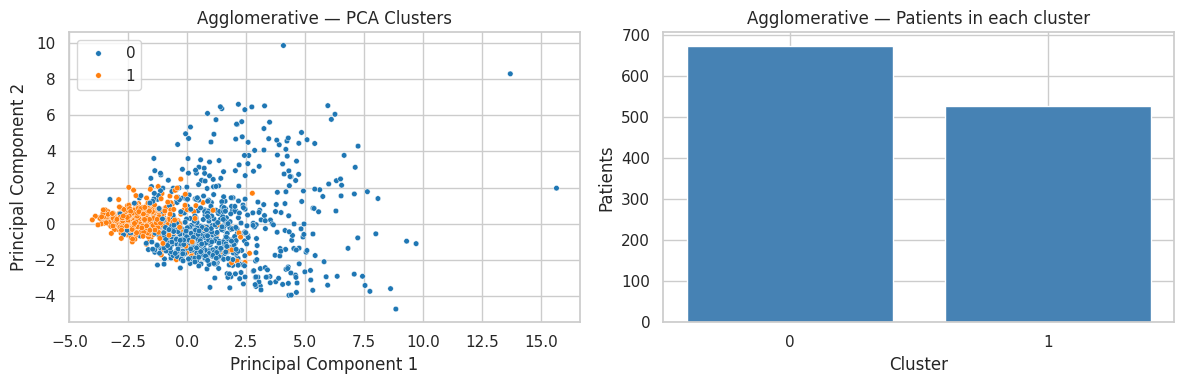

In [9]:
agglomerative = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
agg_labels = agglomerative.fit_predict(X_scaled)

agg_sil = silhouette_score(X_scaled, agg_labels, sample_size=600, random_state=42)
agg_db = davies_bouldin_score(X_scaled, agg_labels)
agg_ch = calinski_harabasz_score(X_scaled, agg_labels)
agg_sizes = pd.Series(agg_labels).value_counts().sort_index()

print("Agglomerative results (Ward linkage)")
print("Silhouette Score:", round(agg_sil, 3))
print("Davies-Bouldin:", round(agg_db, 3))
print("Calinski-Harabasz:", round(agg_ch, 2))
print("Number of patients per cluster:")
print(agg_sizes.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=agg_labels,
                palette="tab10", s=16, ax=axes[0], legend="full")
axes[0].set_title("Agglomerative — PCA Clusters")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")
axes[1].bar(agg_sizes.index.astype(str), agg_sizes.values, color="steelblue")
axes[1].set_title("Agglomerative — Patients in each cluster")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Patients")
plt.tight_layout()
plt.show()

## Step 10 — Linkage strategy comparison + dendrogram
**Ward:** merges clusters to minimize the increase in within-group variance. **Complete:** uses the farthest pair. **Average:** uses average distances. Check cluster sizes: an apparently high score can result from one very tiny group. The dendrogram uses 65 patients because drawing all 1,200 branches is difficult to read.

,Linkage,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest Cluster,Largest Cluster
0,ward,0.052,3.690,76.446,527,673
1,complete,0.478,1.215,23.422,6,1194
2,average,0.569,0.840,21.758,3,1197


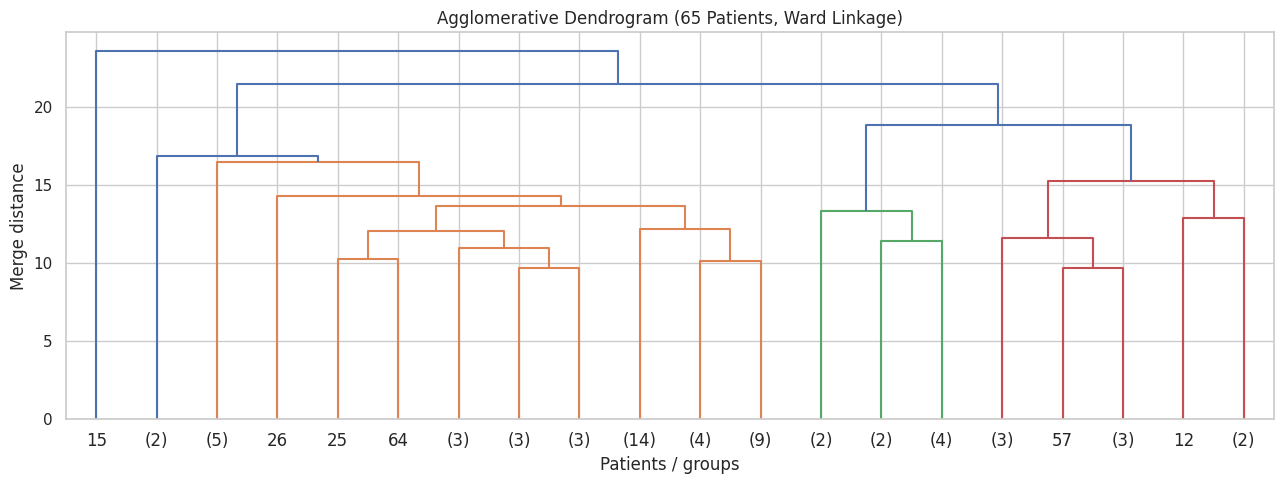

In [10]:
linkage_results = []
for method in ["ward", "complete", "average"]:
    group_model = AgglomerativeClustering(n_clusters=best_k, linkage=method)
    group_labels = group_model.fit_predict(X_scaled)
    group_sizes = pd.Series(group_labels).value_counts()
    linkage_results.append({
        "Linkage": method,
        "Silhouette": silhouette_score(X_scaled, group_labels, sample_size=600, random_state=42),
        "Davies-Bouldin": davies_bouldin_score(X_scaled, group_labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_scaled, group_labels),
        "Smallest Cluster": int(group_sizes.min()),
        "Largest Cluster": int(group_sizes.max())
    })
linkage_table = pd.DataFrame(linkage_results)
display(linkage_table.round(3))

# Dendrogram represents bottom-up merging for a small subset
Z = linkage(X_scaled[:65], method="ward")
plt.figure(figsize=(13, 5))
dendrogram(Z, truncate_mode="lastp", p=20, show_leaf_counts=True)
plt.title("Agglomerative Dendrogram (65 Patients, Ward Linkage)")
plt.xlabel("Patients / groups")
plt.ylabel("Merge distance")
plt.tight_layout()
plt.show()

## Step 11 — Extra algorithm 3: Divisive Hierarchical (Bisecting K-Means)
**Top-down:** Start with one large cluster and split it into smaller clusters until `k` groups remain. We use sklearn's `BisectingKMeans`, a practical **divisive / top-down hierarchical method**, **not** the classical DIANA algorithm. This is **additional** to the professor's two required algorithms.

Divisive (Bisecting K-Means) results
Silhouette Score: 0.121
Davies-Bouldin: 3.295
Calinski-Harabasz: 104.43
Number of patients per cluster:
0    473
1    727


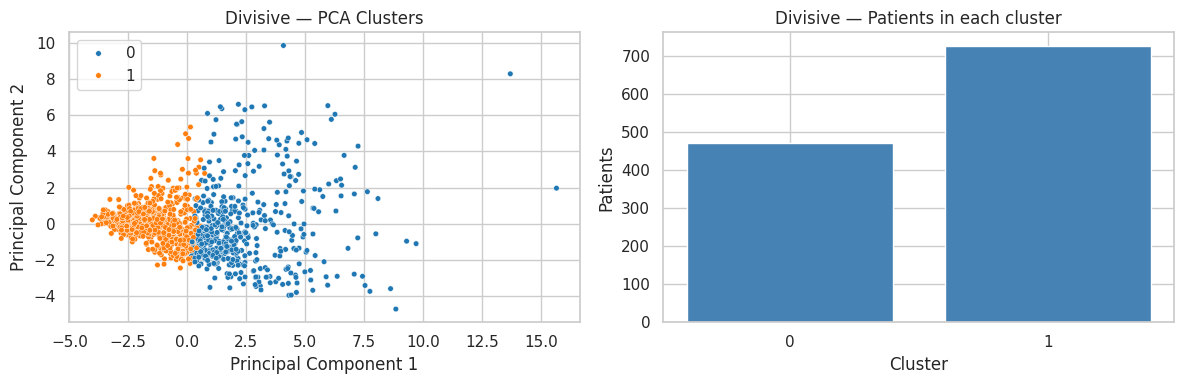

In [11]:
divisive = BisectingKMeans(n_clusters=best_k, n_init=5, random_state=42)
div_labels = divisive.fit_predict(X_scaled)

div_sil = silhouette_score(X_scaled, div_labels, sample_size=600, random_state=42)
div_db = davies_bouldin_score(X_scaled, div_labels)
div_ch = calinski_harabasz_score(X_scaled, div_labels)
div_sizes = pd.Series(div_labels).value_counts().sort_index()

print("Divisive (Bisecting K-Means) results")
print("Silhouette Score:", round(div_sil, 3))
print("Davies-Bouldin:", round(div_db, 3))
print("Calinski-Harabasz:", round(div_ch, 2))
print("Number of patients per cluster:")
print(div_sizes.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=div_labels,
                palette="tab10", s=16, ax=axes[0], legend="full")
axes[0].set_title("Divisive — PCA Clusters")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")
axes[1].bar(div_sizes.index.astype(str), div_sizes.values, color="steelblue")
axes[1].set_title("Divisive — Patients in each cluster")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Patients")
plt.tight_layout()
plt.show()

## Step 12 — Final 3-algorithm comparison (mandatory metrics)
All three are trained on the same 1,200 scaled records with the same `k`, so their scores are comparable. **Higher** Silhouette and Calinski–Harabasz are preferable; **lower** Davies–Bouldin is preferable. Cluster sizes also matter. Do not declare a winner only because of one metric.

Comparison of all three algorithms:


,Algorithm,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest Cluster,Largest Cluster
0,K-Means,2,0.125,3.281,104.347,444,756
1,Agglomerative Hierarchical,2,0.052,3.690,76.446,527,673
2,Divisive (Bisecting K-Means),2,0.121,3.295,104.425,473,727


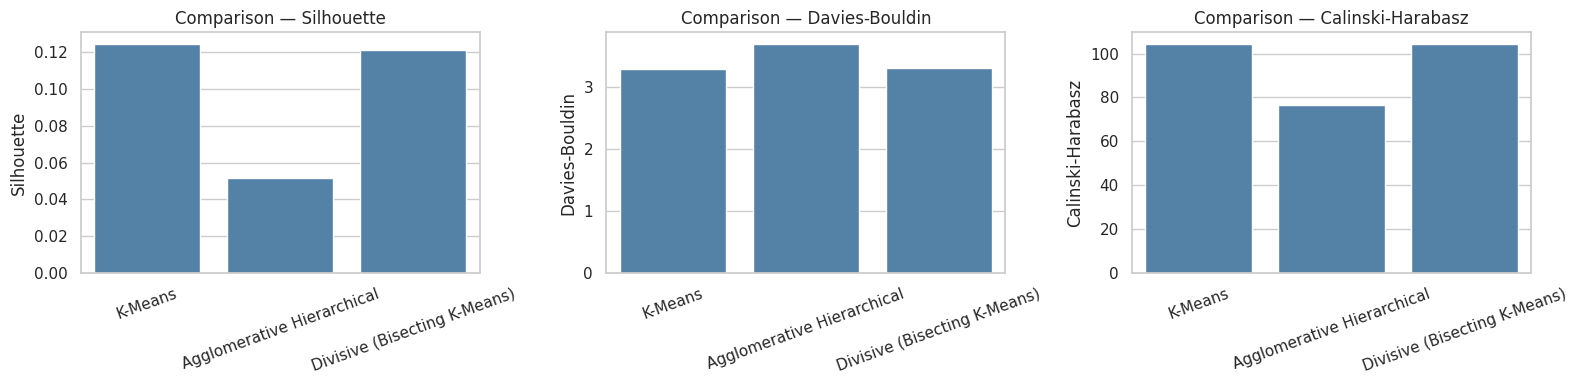

In [12]:
comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "Agglomerative Hierarchical", "Divisive (Bisecting K-Means)"],
    "Clusters": [len(km_sizes), len(agg_sizes), len(div_sizes)],
    "Silhouette": [km_sil, agg_sil, div_sil],
    "Davies-Bouldin": [km_db, agg_db, div_db],
    "Calinski-Harabasz": [km_ch, agg_ch, div_ch],
    "Smallest Cluster": [int(km_sizes.min()), int(agg_sizes.min()), int(div_sizes.min())],
    "Largest Cluster": [int(km_sizes.max()), int(agg_sizes.max()), int(div_sizes.max())]
})

print("Comparison of all three algorithms:")
display(comparison.round(3))
comparison.to_csv(os.path.join(results_folder, "clustering_comparison.csv"), index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, metric in enumerate(["Silhouette", "Davies-Bouldin", "Calinski-Harabasz"]):
    sns.barplot(data=comparison, x="Algorithm", y=metric, color="steelblue", ax=axes[i])
    axes[i].set_title("Comparison — " + metric)
    axes[i].tick_params(axis="x", rotation=20)
    axes[i].set_xlabel("")
plt.tight_layout()
plt.show()

## Step 13 — t-SNE plot (encouraged by rubric)
t-SNE visualises local patterns for **only 400 patients**. Colors are the K-Means labels already obtained. t-SNE does **not** train the clustering model or prove clusters are well separated.

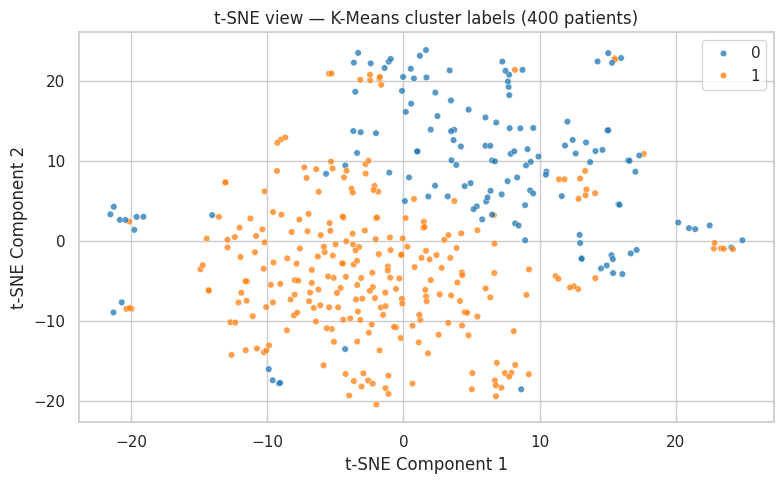

In [13]:
n = min(400, len(X_scaled))
tsne = TSNE(n_components=2, perplexity=25, learning_rate="auto",
            init="pca", max_iter=500, random_state=42)
X_tsne = tsne.fit_transform(X_scaled[:n])

plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=kmeans_labels[:n],
                palette="tab10", s=22, alpha=0.75)
plt.title("t-SNE view — K-Means cluster labels (400 patients)")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.tight_layout()
plt.show()

## Step 14 — Compare real patient features across clusters
This step **interprets** the unsupervised cluster labels after fitting; it does not use ground-truth labels to train clusters. Different algorithms number their clusters differently, so cluster 0 in one is not necessarily cluster 0 in another.


Cluster profiles: K-Means


,age,bmi,income,visits_last_year,annual_premium
Cluster,,,,,
0,50.76,27.42,48756.31,3.02,770.18
1,45.42,26.71,51380.56,1.28,462.25


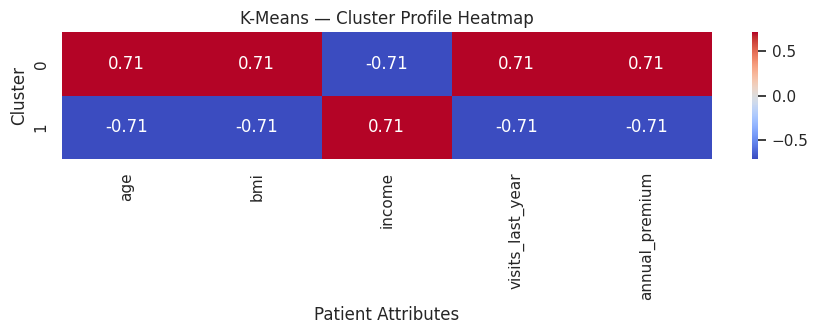


Cluster profiles: Agglomerative


,age,bmi,income,visits_last_year,annual_premium
Cluster,,,,,
0,48.48,27.13,49613.67,2.44,673.88
1,46.02,26.76,51426.00,1.28,451.42


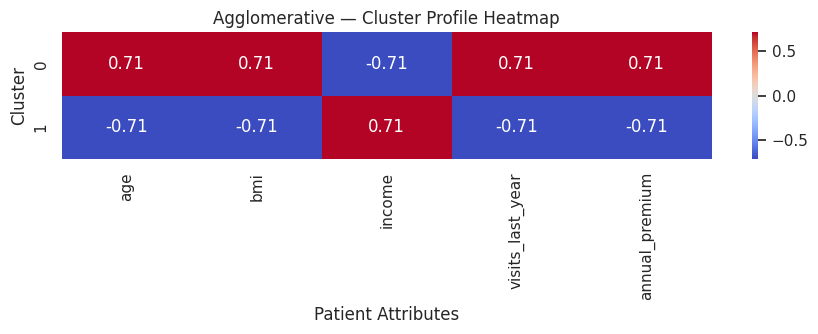


Cluster profiles: Divisive


,age,bmi,income,visits_last_year,annual_premium
Cluster,,,,,
0,50.42,27.45,49178.86,2.96,756.82
1,45.43,26.66,51210.32,1.25,458.66


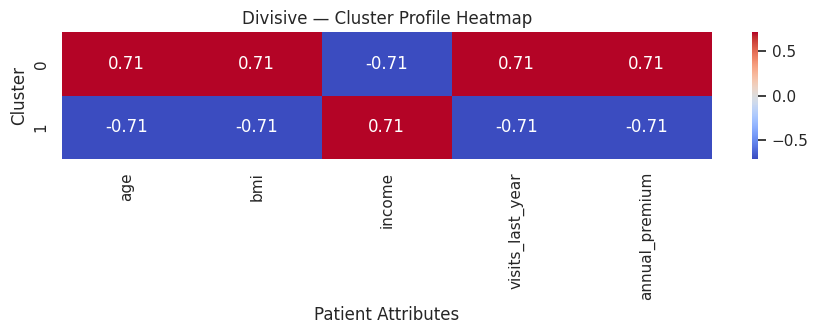

In [14]:
for name, labels in [
    ("K-Means", kmeans_labels),
    ("Agglomerative", agg_labels),
    ("Divisive", div_labels)
]:
    profile = X[["age", "bmi", "income", "visits_last_year", "annual_premium"]].copy()
    profile["Cluster"] = labels
    means = profile.groupby("Cluster").mean().round(2)
    print("\nCluster profiles:", name)
    display(means)
    means.to_csv(os.path.join(results_folder, name.lower() + "_profiles.csv"))

    # Compare column-normalised group averages
    normalised = (means - means.mean()) / means.std().replace(0, 1)
    plt.figure(figsize=(9, 3.5))
    sns.heatmap(normalised.fillna(0), annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title(name + " — Cluster Profile Heatmap")
    plt.xlabel("Patient Attributes")
    plt.ylabel("Cluster")
    plt.tight_layout()
    plt.show()

## Step 15 — Five-fold stability / repeatability check (additional)
Unlike classification, clustering has no usual label-based train/test accuracy. Here we fit each algorithm separately on five disjoint subsets and compare Silhouette scores. **This is a robustness demonstration, not ordinary supervised 5-fold cross-validation or a measure of test accuracy.** Results may vary simply because each subset contains different patients.

In [15]:
from sklearn.model_selection import KFold

fold_results = []
folds = KFold(n_splits=5, shuffle=True, random_state=42)

for fold_number, (train_index, subset_index) in enumerate(folds.split(X_scaled), 1):
    X_fold = X_scaled[subset_index]

    for name, model in [
        ("K-Means", KMeans(n_clusters=best_k, n_init=10, random_state=42)),
        ("Agglomerative", AgglomerativeClustering(n_clusters=best_k, linkage="ward")),
        ("Divisive", BisectingKMeans(n_clusters=best_k, n_init=5, random_state=42))
    ]:
        labels = model.fit_predict(X_fold)
        if 1 < len(np.unique(labels)) < len(labels):
            score = silhouette_score(X_fold, labels)
        else:
            score = np.nan
        fold_results.append({"Fold": fold_number, "Algorithm": name,
                             "Silhouette": score})

stability = pd.DataFrame(fold_results)
print("Silhouette per fold:")
display(stability.pivot(index="Fold", columns="Algorithm", values="Silhouette").round(3))
print("Average and variation across 5 subsets:")
display(stability.groupby("Algorithm")["Silhouette"].agg(["mean", "std"]).round(3))
stability.to_csv(os.path.join(results_folder, "clustering_stability.csv"), index=False)

Silhouette per fold:


Algorithm,Agglomerative,Divisive,K-Means
Fold,,,
1,0.069,0.142,0.135
2,0.051,0.132,0.132
3,0.033,0.087,0.097
4,0.078,0.178,0.178
5,0.062,0.168,0.168


Average and variation across 5 subsets:


,mean,std
Algorithm,,
Agglomerative,0.059,0.018
Divisive,0.141,0.035
K-Means,0.142,0.032


## Step 16 — Final student-written interpretation (fill this in before submission)

After running the code, replace the blanks using the actual outputs:

- **Dataset & sample:** The original file has ____ rows; clustering was run on ____ patients because agglomerative clustering is computationally expensive.
- **Number of clusters:** We chose `k=____` based on the elbow plot and silhouette curve because ____.
- **K-Means:** The Silhouette is ____ and the largest cluster has ____ patients. This suggests ____.
- **Agglomerative:** Ward-linkage Silhouette is ____. The dendrogram shows ____.
- **Divisive:** Bisecting K-Means Silhouette is ____. It divides groups top-down rather than merging bottom-up.
- **Comparison:** The three methods disagree/agree because ____. Note any extremely small cluster.
- **Interpretation:** Cluster ____ tends to have higher ____ and lower ____, based on the profile table.
- **Limitations:** The 1,200-person sample may not reflect all 100,000 patients; PCA/t-SNE plots are 2D summaries, not proof of cluster quality.

### Simple viva answers
**Q:** Why StandardScaler? **A:** Clustering uses distances and we do not want large-number features like income to dominate smaller-number features like BMI.  
**Q:** Why are there no accuracy scores? **A:** Clustering is unsupervised, so we don't have known class labels during training.  
**Q:** Agglomerative versus divisive? **A:** Agglomerative starts with single points and merges groups; divisive starts with one group and repeatedly splits it.  
**Q:** Is `BisectingKMeans` the same as classical DIANA? **A:** No. It is a practical top-down hierarchical variant implemented in scikit-learn.  
**Q:** Which methods does the rubric require? **A:** K-Means and agglomerative hierarchical clustering; divisive is our extra comparative analysis.

**Academic-integrity note:** AI assistance was used for programming scaffolding and simplification. The team must write its own observations, interpretations, and conclusions.